In [2]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import yaml
import os

In [3]:
import torch
from deep_hedging.black_scholes import black_scholes_call_price
from deep_hedging.delta import bs_hedge_policy
from deep_hedging.risk import entropic_risk
from deep_hedging.gbm import simulate_gbm
from deep_hedging.engine import pnl
from deep_hedging.payoffs import call_payoff
from deep_hedging.nn_policy import build_nn, nn_policy
from deep_hedging.features import make_features

In [4]:
def loading_setup(run_path):
# Load config:
    run_path = Path(run_path)
    config_path = os.path.join(run_path, "config.yaml")
    with open(config_path) as f:
        config = yaml.safe_load(f)

    S0 = config["market"]["S0"]
    mu = config["market"]["mu"]
    
    true_sigma = 0.4
    sigma = config["market"]["sigma"]
    
    T = config["market"]["T"]
    n_steps = config["market"]["n_steps"]

    moneyness_scale = config["input_scale"]["moneyness_scale"]
    tau_scale = config["input_scale"]["tau_scale"]

    K = config["option"]["K"]

    lam = config["risk"]["lam"]
    alpha = config["risk"]["alpha"]

    n_paths = config["test"]["n_paths"]
    n_hidden = config["network"]["n_hidden"]
    n_layers = config["network"]["n_layers"]

    bs_price = black_scholes_call_price(S=torch.tensor(S0, dtype=torch.float32), K=K, tau=torch.tensor(T, dtype=torch.float32), sigma=sigma).item()
    # print(f"Black Scholes Price: {bs_price}")

    # Test paths
    torch.manual_seed(config["test_seed"])
    test_t, test_S = simulate_gbm(S0, mu, true_sigma, T, n_steps, n_paths)

    payoff_ = call_payoff(K, test_S[:, -1, 0])

    # BS hedge
    bs_delta_04 = bs_hedge_policy(S=test_S, K=K, T=T, t=test_t, sigma=true_sigma)[:, :-1, :]
    bs_delta_02 = bs_hedge_policy(S=test_S, K=K, T=T, t=test_t, sigma=sigma)[:, :-1, :]

    # NN hedge
    features = make_features(S=test_S, t=test_t, T=T, K=K, moneyness_scale=moneyness_scale, tau_scale=tau_scale)

    model = build_nn(n_inputs=3, n_outputs=1, n_hidden=n_hidden, n_layers=n_layers)

    model.load_state_dict(torch.load(run_path / "model.pt"))
    model.eval()
    with torch.no_grad():
        nn_delta = nn_policy(model, features)
    
    return {
        "config": config,
        "S0": S0, "mu": mu, "sigma": sigma, "T": T, "n_steps": n_steps,
        "moneyness_scale": moneyness_scale, "tau_scale": tau_scale,
        "K": K, "lam": lam, "alpha": alpha,
        "n_paths": n_paths, "n_hidden": n_hidden, "n_layers": n_layers,
        "bs_price": bs_price,
        "test_t": test_t, 
        "test_S": test_S,
        "payoff_": payoff_,
        "bs_delta02": bs_delta_02,
        "bs_delta04": bs_delta_04,
        "features": features,
        "model": model,
        "nn_delta": nn_delta
    }

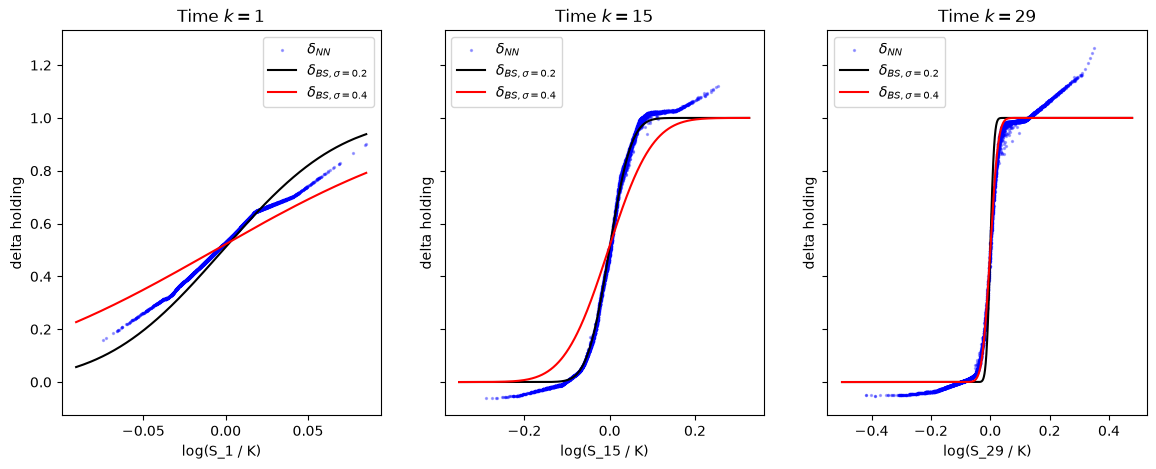

In [5]:
def plot_delta_comparison(run_path, timesteps=[1, 15, 29], model_name=None, save_dir=None, axes=None, is_standalone=True):

    data = loading_setup(run_path)
    test_S = data["test_S"]
    nn_delta = data["nn_delta"]
    bs_delta02 = data["bs_delta02"]
    bs_delta04 = data["bs_delta04"]
    K = data["K"]

    g = torch.Generator().manual_seed(1)
    N = test_S.shape[0]
    sub = torch.randperm(N, generator=g)[:5000]

    if axes is None:
        fig, axes = plt.subplots(1, len(timesteps), figsize=(14, 5), sharey=True)
        

    for k, ax in zip(timesteps, axes):
        x = torch.log(test_S[:, k, 0] / K)
        y_nn = nn_delta[:, k, 0]
        y_bs02 = bs_delta02[:, k, 0]
        y_bs04 = bs_delta04[:, k, 0]

        ax.scatter(x[sub], y_nn[sub], s=2, color="blue", alpha=0.3, label=r"$\delta_{NN}$")

        order = torch.argsort(x)
        ax.plot(x[order], y_bs02[order], color="black", label=r"$\delta_{BS, \sigma=0.2}$")
        ax.plot(x[order], y_bs04[order], color="red", label=r"$\delta_{BS, \sigma=0.4}$")

        # ax.set_title(f"NN_{model_name} vs BS delta Hedging at time k={k}")
        ax.set_title(f"Time $k = {k}$")
        ax.set_xlabel(f"log(S_{k} / K)")
        ax.set_ylabel(f"delta holding")

        ax.legend()

    if is_standalone and save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        save_name = "delta_comparison_" + "_".join(f"k{k}" for k in timesteps) + ".png"
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, save_name), dpi=150, bbox_inches="tight")
        plt.show()

    return axes

delta_comp_raw = plot_delta_comparison(run_path=Path("../runs/entropic_nocost_scaled_seed0"), model_name="Raw Inputs Model", timesteps=[1, 15, 29], save_dir=None)

Near the money, the learnt hedge trained on 0.2 vol follows bs_delta_02vol and it is just as wrong as the bs_delta_02vol compared to the bs_delta_04vol.

In the tails, it goes negative out of the money, at k=15 and k=29, and it goes above 1 in the money. A call delta is in [0,1].

Those are paths reached with sigma=0.4 and not by paths generated with sigma=0.2 so the network is guessing there. 

Near the money, the learnt hedge trained on vol = 0.2 follows the Black-Scholes delta at vol = 0.2, so it is just as wrong as that delta compared to the true hedge at vol = 0.4. This part is ordinary model risk, any hedge built on the wrong volatility has it.

In the tails, at k = 15 and k = 29, it goes negative out of the money and above 1 in the money, but a call delta is always in [0, 1], so these holdings are impossible.

Those are moneyness values that vol = 0.4 paths reach but vol = 0.2 training paths almost never do, so the network is guessing there and it continues in a straight line from the edge of its training data.  ( ReLU networks extrapolate linearly far from their data. [and Xu et al. (ICLR 2021)] )

Black Scholes Price: 2.2871475219726562


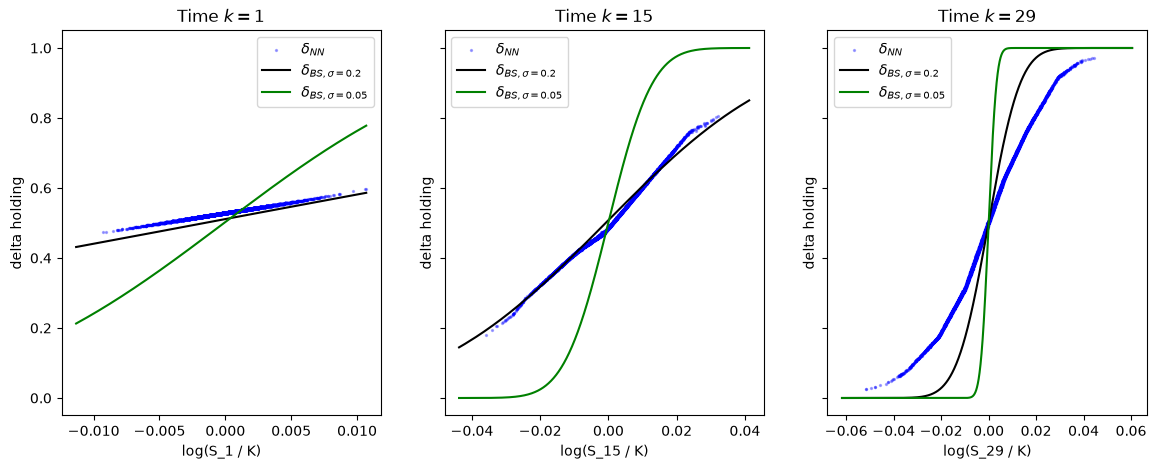

In [6]:
def loading_setup(run_path):
# Load config:
    run_path = Path(run_path)
    config_path = os.path.join(run_path, "config.yaml")
    with open(config_path) as f:
        config = yaml.safe_load(f)

    S0 = config["market"]["S0"]
    mu = config["market"]["mu"]
    
    true_sigma = 0.05
    sigma = config["market"]["sigma"]
    
    T = config["market"]["T"]
    n_steps = config["market"]["n_steps"]

    moneyness_scale = config["input_scale"]["moneyness_scale"]
    tau_scale = config["input_scale"]["tau_scale"]

    K = config["option"]["K"]

    lam = config["risk"]["lam"]
    alpha = config["risk"]["alpha"]

    n_paths = config["test"]["n_paths"]
    n_hidden = config["network"]["n_hidden"]
    n_layers = config["network"]["n_layers"]

    bs_price = black_scholes_call_price(S=torch.tensor(S0, dtype=torch.float32), K=K, tau=torch.tensor(T, dtype=torch.float32), sigma=sigma).item()
    print(f"Black Scholes Price: {bs_price}")

    # Test paths
    torch.manual_seed(config["test_seed"])
    test_t, test_S = simulate_gbm(S0, mu, true_sigma, T, n_steps, n_paths)

    payoff_ = call_payoff(K, test_S[:, -1, 0])

    # BS hedge
    bs_delta_005 = bs_hedge_policy(S=test_S, K=K, T=T, t=test_t, sigma=true_sigma)[:, :-1, :]
    bs_delta_02 = bs_hedge_policy(S=test_S, K=K, T=T, t=test_t, sigma=sigma)[:, :-1, :]

    # NN hedge
    features = make_features(S=test_S, t=test_t, T=T, K=K, moneyness_scale=moneyness_scale, tau_scale=tau_scale)

    model = build_nn(n_inputs=3, n_outputs=1, n_hidden=n_hidden, n_layers=n_layers)

    model.load_state_dict(torch.load(run_path / "model.pt"))
    model.eval()
    with torch.no_grad():
        nn_delta = nn_policy(model, features)
    
    return {
        "config": config,
        "S0": S0, "mu": mu, "sigma": sigma, "T": T, "n_steps": n_steps,
        "moneyness_scale": moneyness_scale, "tau_scale": tau_scale,
        "K": K, "lam": lam, "alpha": alpha,
        "n_paths": n_paths, "n_hidden": n_hidden, "n_layers": n_layers,
        "bs_price": bs_price,
        "test_t": test_t, 
        "test_S": test_S,
        "payoff_": payoff_,
        "bs_delta02": bs_delta_02,
        "bs_delta005": bs_delta_005,
        "features": features,
        "model": model,
        "nn_delta": nn_delta
    }

def plot_delta_comparison(run_path, timesteps=[1, 15, 29], model_name=None, save_dir=None, axes=None, is_standalone=True):

    data = loading_setup(run_path)
    test_S = data["test_S"]
    nn_delta = data["nn_delta"]
    bs_delta02 = data["bs_delta02"]
    bs_delta005 = data["bs_delta005"]
    K = data["K"]

    g = torch.Generator().manual_seed(1)
    N = test_S.shape[0]
    sub = torch.randperm(N, generator=g)[:5000]

    if axes is None:
        fig, axes = plt.subplots(1, len(timesteps), figsize=(14, 5), sharey=True)
        

    for k, ax in zip(timesteps, axes):
        x = torch.log(test_S[:, k, 0] / K)
        y_nn = nn_delta[:, k, 0]
        y_bs02 = bs_delta02[:, k, 0]
        y_bs005 = bs_delta005[:, k, 0]

        ax.scatter(x[sub], y_nn[sub], s=2, color="blue", alpha=0.3, label=r"$\delta_{NN}$")

        order = torch.argsort(x)
        ax.plot(x[order], y_bs02[order], color="black", label=r"$\delta_{BS, \sigma=0.2}$")
        ax.plot(x[order], y_bs005[order], color="green", label=r"$\delta_{BS, \sigma=0.05}$")

        # ax.set_title(f"NN_{model_name} vs BS delta Hedging at time k={k}")
        ax.set_title(f"Time $k = {k}$")
        ax.set_xlabel(f"log(S_{k} / K)")
        ax.set_ylabel(f"delta holding")

        ax.legend()

    if is_standalone and save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        save_name = "delta_comparison_" + "_".join(f"k{k}" for k in timesteps) + ".png"
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, save_name), dpi=150, bbox_inches="tight")
        plt.show()

    return axes

delta_comp_raw = plot_delta_comparison(run_path=Path("../runs/entropic_nocost_scaled_seed0"), model_name="Raw Inputs Model", timesteps=[1, 15, 29], save_dir=None)